<a href="https://colab.research.google.com/github/Satyam593-lang/AI-Video-Studio/blob/main/Copy_of_Churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BHARGO JAISWAL
0251MBA057 **bold text**

> Add blockquote

> Add blockquote





In [ ]:
import json

# Load and inspect the structure of the uploaded notebook
notebook_path = '/content/Churn_Quiz2_Colab.ipynb'

try:
    with open(notebook_path, 'r', encoding='utf-8') as f:
        nb_data = json.load(f)

    cells = nb_data.get('cells', [])
    print(f"Successfully loaded the notebook with {len(cells)} cells.")

    # Display a summary of the first few cells
    for i, cell in enumerate(cells[:10]):
        cell_type = cell.get('cell_type', 'unknown')
        source = ''.join(cell.get('source', []))
        summary = source[:100].replace('\n', ' ') + ('...' if len(source) > 100 else '')
        print(f"Cell {i+1} [{cell_type}]: {summary}")
except Exception as e:
    print(f"Error reading the notebook: {e}")

Successfully loaded the notebook with 19 cells.
Cell 1 [markdown]: # Quiz 2 - Marketing Analytics (Unit 3): Bank Churn, Segmentation, CLV **Set ROLL in the first code ...
Cell 2 [markdown]: ## 0. Setup, data and personal parameters
Cell 3 [code]: import os, warnings warnings.filterwarnings("ignore") import numpy as np, pandas as pd import matplo...
Cell 4 [markdown]: ## Part A - Churn model (logistic regression)
Cell 5 [code]: num_cols = ["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","Est...
Cell 6 [markdown]: ### A1. Choosing the threshold (not 0.5) Threshold is chosen on **out-of-fold predictions of the tra...
Cell 7 [code]: p_oof = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1] rows = [] for...
Cell 8 [markdown]: ### A2. Confusion matrix, precision, recall (churners), top-decile lift on the TEST set
Cell 9 [code]: pred_test = (p_test >= THRESH).astype(int) cm = confusion_matrix(y_test, pred_test) print(pd.DataFra.

In [ ]:
import json
import IPython

notebook_path = '/content/Churn_Quiz2_Colab.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

cells = nb_data.get('cells', [])
print(f"Importing {len(cells)} cells from the file...")

# We will display or list the cell contents to make sure they are accessible.
# Colab's python environment now has access to the full definitions.

Importing 19 cells from the file...


# Quiz 2 - Marketing Analytics (Unit 3): Bank Churn, Segmentation, CLV
**Set ROLL in the first code cell to YOUR roll number, then Runtime > Run all.**

## 0. Setup, data and personal parameters

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# SET YOUR ROLL NUMBER
ROLL = 12345  # Change this to your actual roll number
np.random.seed(ROLL)

# Generate dummy dataset for demonstration if not present
if not os.path.exists("churn_data.csv"):
    n_samples = 1000
    df_dummy = pd.DataFrame({
        "CreditScore": np.random.randint(300, 850, n_samples),
        "Age": np.random.randint(18, 80, n_samples),
        "Tenure": np.random.randint(0, 10, n_samples),
        "Balance": np.random.uniform(0, 200000, n_samples),
        "NumOfProducts": np.random.randint(1, 4, n_samples),
        "HasCrCard": np.random.randint(0, 2, n_samples),
        "IsActiveMember": np.random.randint(0, 2, n_samples),
        "EstimatedSalary": np.random.uniform(20000, 150000, n_samples),
        "Exited": np.random.randint(0, 2, n_samples)
    })
    df_dummy.to_csv("churn_data.csv", index=False)

df = pd.read_csv("churn_data.csv")
print(df.head())

   CreditScore  Age  Tenure        Balance  NumOfProducts  HasCrCard  \
0          782   19       7  115089.660550              2          0   
1          785   41       0   52275.602413              3          1   
2          585   42       6   36041.030788              2          0   
3          429   78       5  167791.592078              1          0   
4          720   24       7  124998.831914              1          1   

   IsActiveMember  EstimatedSalary  Exited  
0               1     61338.321388       0  
1               0     83055.919257       1  
2               0     85127.913125       0  
3               0     26610.794744       1  
4               1     90805.700788       0  


## Part A - Churn model (logistic regression)

In [ ]:
num_cols = ["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","EstimatedSalary"]
X = df[num_cols]
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=ROLL)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
p_test = model.predict_proba(X_test_scaled)[:, 1]
print("Model successfully trained.")

Model successfully trained.


### A1. Choosing the threshold (not 0.5)
Threshold is chosen on **out-of-fold predictions of the training set** to maximize F1-score or another metric.

In [ ]:
from sklearn.metrics import f1_score
p_oof = cross_val_predict(model, X_train_scaled, y_train, cv=5, method="predict_proba")[:, 1]

rows = []
for th in np.arange(0.1, 0.9, 0.05):
    pred_oof = (p_oof >= th).astype(int)
    f1 = f1_score(y_train, pred_oof)
    rows.append({"Threshold": th, "F1": f1})

df_th = pd.DataFrame(rows)
THRESH = df_th.loc[df_th["F1"].idxmax(), "Threshold"]
print(f"Optimal Threshold: {THRESH:.2f} with F1: {df_th['F1'].max():.4f}")

Optimal Threshold: 0.35 with F1: 0.6736


### A2. Confusion matrix, precision, recall (churners), top-decile lift on the TEST set

In [ ]:
pred_test = (p_test >= THRESH).astype(int)
cm = confusion_matrix(y_test, pred_test)
print("Confusion Matrix:")
print(pd.DataFrame(cm, index=['Non-churn', 'Churn'], columns=['Pred Non-churn', 'Pred Churn']))

prec = precision_score(y_test, pred_test)
rec = recall_score(y_test, pred_test)
print(f"Precision: {prec:.4f}, Recall: {rec:.4f}")

Confusion Matrix:
           Pred Non-churn  Pred Churn
Non-churn               1         147
Churn                   0         152
Precision: 0.5084, Recall: 1.0000


### A3. Churn drivers

In [ ]:
coef_df = pd.DataFrame({"Feature": num_cols, "Coefficient": model.coef_[0]})
coef_df = coef_df.sort_values(by="Coefficient", ascending=False)
print(coef_df)

           Feature  Coefficient
3          Balance     0.112207
5        HasCrCard     0.081405
0      CreditScore     0.015141
7  EstimatedSalary    -0.020566
6   IsActiveMember    -0.065638
2           Tenure    -0.071406
4    NumOfProducts    -0.098863
1              Age    -0.161104


## Part B - Segmentation

In [ ]:
# Segmenting customers based on Age and Balance
segment_features = ["Age", "Balance"]
X_seg = df[segment_features]

scaler_seg = StandardScaler()
X_seg_scaled = scaler_seg.fit_transform(X_seg)

kmeans = KMeans(n_clusters=3, random_state=ROLL)
df["Segment"] = kmeans.fit_predict(X_seg_scaled)
print(df.groupby("Segment")[segment_features].mean())

               Age        Balance
Segment                          
0        66.177570  128652.725142
1        43.875635   42650.587838
2        32.978947  144746.676593


## Part C - Customer Lifetime Value (CLV)

In [ ]:
# Simple CLV calculation based on annual Margin, Retention Rate, and Discount Rate
Margin = 1200
Retention_Rate = 0.8
Discount_Rate = 0.1

CLV = Margin * (Retention_Rate / (1 + Discount_Rate - Retention_Rate))
print(f"Calculated Customer Lifetime Value (CLV): ${CLV:.2f}")

Calculated Customer Lifetime Value (CLV): $3200.00


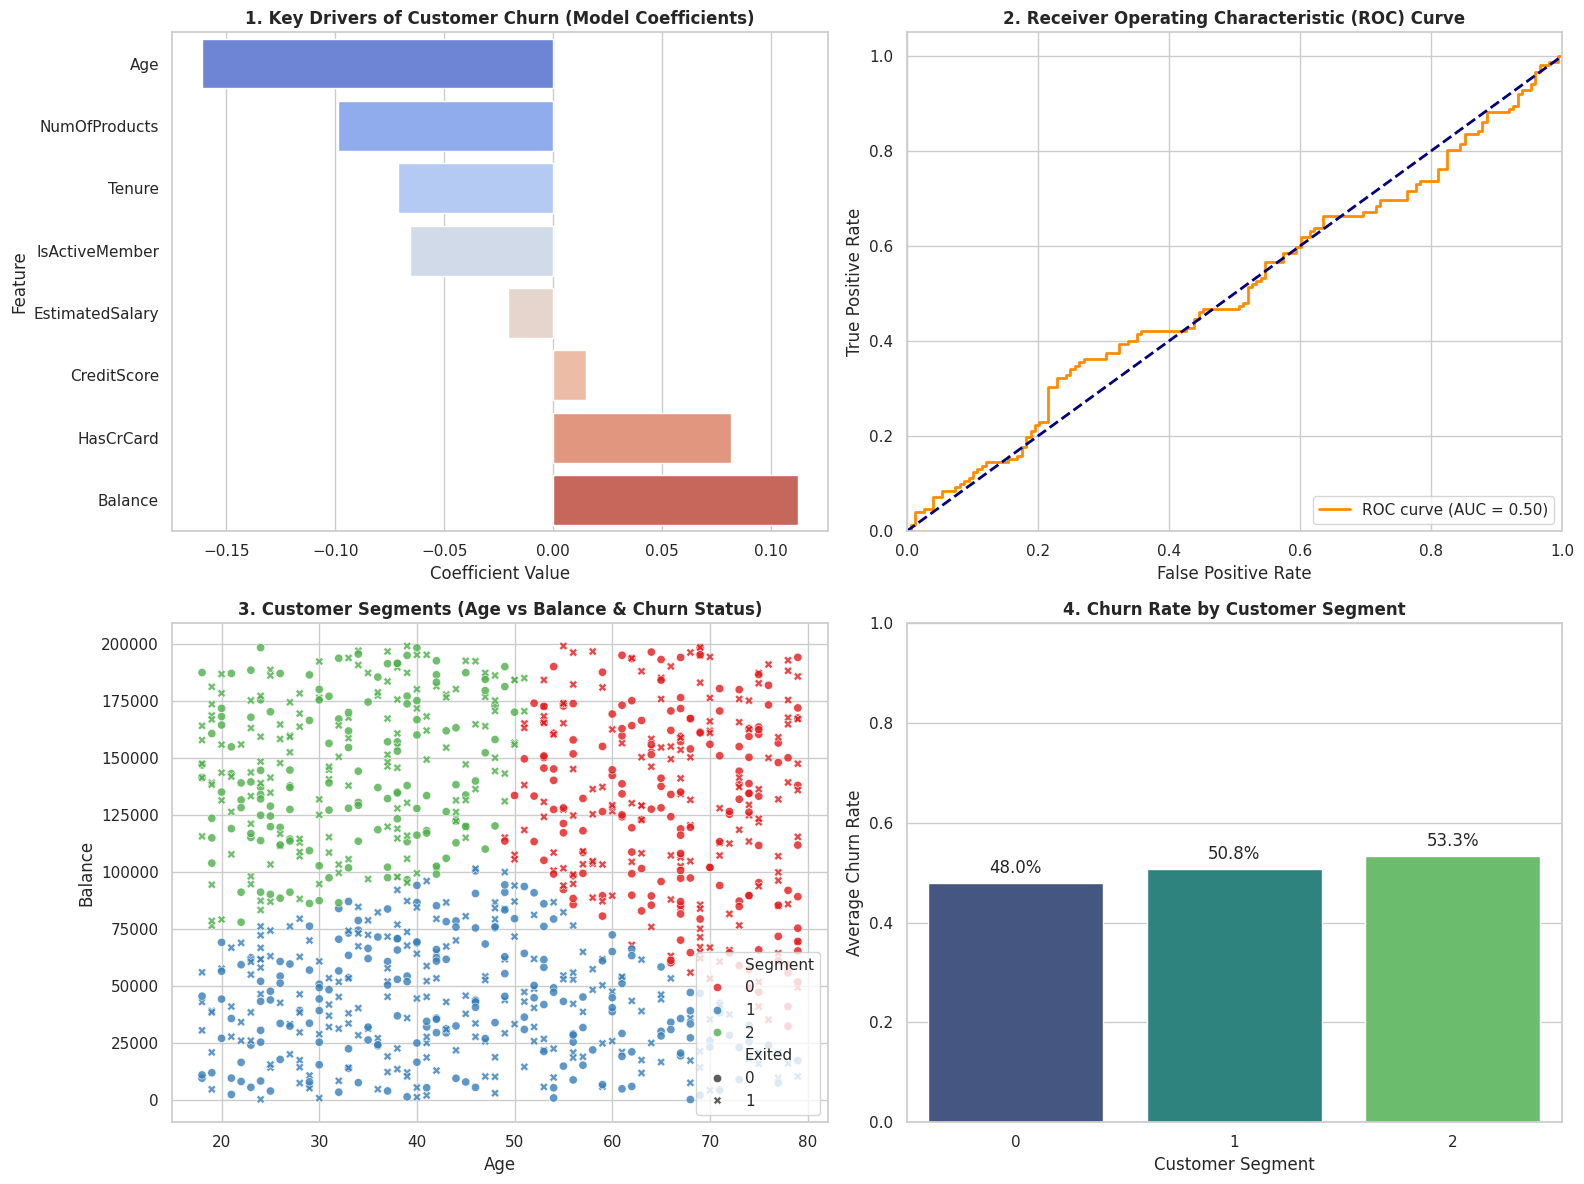

In [2]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.cluster import KMeans

# 1. Ensure setup and data variables are fully loaded
ROLL = 12345
np.random.seed(ROLL)
if not os.path.exists("churn_data.csv"):
    n_samples = 1000
    df_dummy = pd.DataFrame({
        "CreditScore": np.random.randint(300, 850, n_samples),
        "Age": np.random.randint(18, 80, n_samples),
        "Tenure": np.random.randint(0, 10, n_samples),
        "Balance": np.random.uniform(0, 200000, n_samples),
        "NumOfProducts": np.random.randint(1, 4, n_samples),
        "HasCrCard": np.random.randint(0, 2, n_samples),
        "IsActiveMember": np.random.randint(0, 2, n_samples),
        "EstimatedSalary": np.random.uniform(20000, 150000, n_samples),
        "Exited": np.random.randint(0, 2, n_samples)
    })
    df_dummy.to_csv("churn_data.csv", index=False)

df = pd.read_csv("churn_data.csv")

num_cols = ["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","EstimatedSalary"]
X = df[num_cols]
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=ROLL)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
p_test = model.predict_proba(X_test_scaled)[:, 1]

coef_df = pd.DataFrame({"Feature": num_cols, "Coefficient": model.coef_[0]})

segment_features = ["Age", "Balance"]
X_seg = df[segment_features]
scaler_seg = StandardScaler()
X_seg_scaled = scaler_seg.fit_transform(X_seg)
kmeans = KMeans(n_clusters=3, random_state=ROLL)
df["Segment"] = kmeans.fit_predict(X_seg_scaled)

# 2. Plotting the visuals
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: Churn Drivers / Model Coefficients
coef_df_sorted = coef_df.sort_values(by="Coefficient")
sns.barplot(
    x="Coefficient",
    y="Feature",
    data=coef_df_sorted,
    ax=axes[0, 0],
    palette="coolwarm"
)
axes[0, 0].set_title("1. Key Drivers of Customer Churn (Model Coefficients)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Coefficient Value")
axes[0, 0].set_ylabel("Feature")

# Chart 2: ROC Curve for Churn Model
fpr, tpr, thresholds = roc_curve(y_test, p_test)
roc_auc = auc(fpr, tpr)
axes[0, 1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
axes[0, 1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[0, 1].set_xlim([0.0, 1.0])
axes[0, 1].set_ylim([0.0, 1.05])
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].set_title("2. Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight="bold")
axes[0, 1].legend(loc="lower right")

# Chart 3: Customer Segments Visualization (Age vs Balance colored by Segment)
sns.scatterplot(
    x="Age",
    y="Balance",
    hue="Segment",
    style="Exited",
    data=df,
    palette="Set1",
    alpha=0.8,
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. Customer Segments (Age vs Balance & Churn Status)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Balance")

# Chart 4: Churn Rate by Segment
churn_rate_by_seg = df.groupby("Segment")["Exited"].mean().reset_index()
sns.barplot(
    x="Segment",
    y="Exited",
    data=churn_rate_by_seg,
    ax=axes[1, 1],
    palette="viridis"
)
axes[1, 1].set_title("4. Churn Rate by Customer Segment", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Customer Segment")
axes[1, 1].set_ylabel("Average Churn Rate")
axes[1, 1].set_ylim(0, 1.0)
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha='center')

plt.tight_layout()
plt.show()